# UrbanPulse AI — What-if Engine

## Hypothetical Scenario Analysis for PM2.5 Forecasting

**Project:** UrbanPulse AI  
**Dataset:** UCI Beijing Multi-Site Air Quality  
**Target station:** Aotizhongxin  
**Forecast horizon:** One hour ahead  
**Experiment stage:** Milestone 8 — What-if Engine

### 8.1 Research Objective

This notebook explores how hypothetical changes in current-hour PM2.5 measurements across monitoring stations affect the predictions of the existing multi-station Random Forest model.

The experiment uses a previously trained model and saved test data wherever possible. It compares the original prediction against controlled scenarios while holding all other inputs constant.

These scenarios represent model sensitivity under specified assumptions. They do not establish causal effects, simulate a complete atmospheric system, or guarantee that the hypothetical conditions could occur in reality.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

PROJECT_ROOT = Path(r"C:\UrbanPulse-AI")
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"

required_files = {
    "Test diagnostics": (
        REPORTS_DIR / "spatial_test_predictions_diagnostics.csv"
    ),
    "Spatial metrics": (
        REPORTS_DIR / "spatial_forecasting_metrics.csv"
    ),
    "Station importance": (
        REPORTS_DIR / "spatial_test_permutation_importance.csv"
    ),
}

for name, path in required_files.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

print("\nProject root exists:", PROJECT_ROOT.exists())
print("Models directory exists:", MODELS_DIR.exists())

Test diagnostics: FOUND
  C:\UrbanPulse-AI\reports\spatial_test_predictions_diagnostics.csv
Spatial metrics: FOUND
  C:\UrbanPulse-AI\reports\spatial_forecasting_metrics.csv
Station importance: FOUND
  C:\UrbanPulse-AI\reports\spatial_test_permutation_importance.csv

Project root exists: True
Models directory exists: True


In [2]:
model_files = sorted(
    path for path in MODELS_DIR.rglob("*")
    if path.is_file()
)

print("Files found in models directory:", len(model_files))

for path in model_files:
    print(path.relative_to(PROJECT_ROOT))

Files found in models directory: 5
models\.gitkeep
models\urbanpulse_lstm_pm25.keras
models\urbanpulse_spatial_imputer.joblib
models\urbanpulse_spatial_rf.joblib
models\urbanpulse_target_only_rf.joblib


In [3]:
diagnostics_path = (
    REPORTS_DIR / "spatial_test_predictions_diagnostics.csv"
)

if not diagnostics_path.exists():
    raise FileNotFoundError(
        f"Missing diagnostics file: {diagnostics_path}"
    )

diagnostics = pd.read_csv(diagnostics_path)

print("Shape:", diagnostics.shape)
print("Columns:", diagnostics.columns.tolist())
print("\nFirst five rows:")
display(diagnostics.head())

print("\nMissing values:")
display(diagnostics.isna().sum().to_frame("Missing values"))

Shape: (5139, 8)
Columns: ['Target_Time', 'Actual_PM25', 'Persistence_Prediction', 'Target_Only_RF_Prediction', 'Multi_Station_RF_Prediction', 'Multi_Station_Residual', 'Actual_PM25_Group', 'Month']

First five rows:


,Target_Time,Actual_PM25,Persistence_Prediction,Target_Only_RF_Prediction,Multi_Station_RF_Prediction,Multi_Station_Residual,Actual_PM25_Group,Month
0,2016-07-24 20:00:00,66.0,129.0,123.804465,114.234789,-48.234789,>35–75,2016-07
1,2016-07-24 21:00:00,73.0,66.0,69.483902,70.915548,2.084452,>35–75,2016-07
2,2016-07-24 22:00:00,82.0,73.0,74.741497,69.856104,12.143896,>75–150,2016-07
3,2016-07-24 23:00:00,73.0,82.0,83.179421,76.007572,-3.007572,>35–75,2016-07
4,2016-07-25 00:00:00,55.0,73.0,74.741497,69.660559,-14.660559,>35–75,2016-07



Missing values:


,Missing values
Target_Time,0
Actual_PM25,0
Persistence_Prediction,0
Target_Only_RF_Prediction,0
Multi_Station_RF_Prediction,0
Multi_Station_Residual,0
Actual_PM25_Group,0
Month,0


In [4]:
from pathlib import Path
import joblib
import json

PROJECT_ROOT = Path(r"C:\UrbanPulse-AI")
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

model = joblib.load(
    MODELS_DIR / "urbanpulse_spatial_rf.joblib"
)

imputer = joblib.load(
    MODELS_DIR / "urbanpulse_spatial_imputer.joblib"
)

with open(
    REPORTS_DIR / "spatial_rf_metadata.json",
    encoding="utf-8"
) as f:
    metadata = json.load(f)

print("Model type:", type(model).__name__)
print("Imputer type:", type(imputer).__name__)
print("Number of input features:", metadata["n_features"])
print("Input feature order:", metadata["input_features"])
print("Model feature count:", model.n_features_in_)
print("Imputer feature count:", imputer.n_features_in_)

assert model.n_features_in_ == metadata["n_features"]
assert imputer.n_features_in_ == metadata["n_features"]
assert list(imputer.feature_names_in_) == metadata["input_features"]

print("\nArtifact verification passed.")

Model type: RandomForestRegressor
Imputer type: SimpleImputer
Number of input features: 12
Input feature order: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Model feature count: 12
Imputer feature count: 12

Artifact verification passed.


### 8.2 Scenario Design and Baseline

The saved multi-station Random Forest estimates Aotizhongxin PM2.5 one hour ahead from current-hour PM2.5 readings at 12 monitoring stations.

The baseline scenario uses the original observed station measurements. Alternative scenarios modify selected station readings by specified percentages while holding the other station readings constant.

The experiment evaluates prediction sensitivity under controlled hypothetical inputs. It does not establish causal effects or account for atmospheric feedback, meteorological changes, or pollutant transport beyond what the trained model has learned.

In [5]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(r"C:\UrbanPulse-AI")
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

model = joblib.load(MODELS_DIR / "urbanpulse_spatial_rf.joblib")
imputer = joblib.load(MODELS_DIR / "urbanpulse_spatial_imputer.joblib")

with open(REPORTS_DIR / "spatial_rf_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

station_features = metadata["input_features"]

data_path = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "beijing"
    / "extracted"
    / "PRSA_Data_20130301-20170228"
)

station_files = sorted(data_path.glob("PRSA_Data_*_20130301-20170228.csv"))

print("Station files found:", len(station_files))
for path in station_files:
    print(path.name)

Station files found: 12
PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv


In [6]:
if len(station_files) != 12:
    raise FileNotFoundError(
        f"Expected 12 station CSVs, found {len(station_files)} "
        f"in {data_path}"
    )

station_frames = []

for path in station_files:
    frame = pd.read_csv(path)

    station_name = path.name.replace(
        "PRSA_Data_", ""
    ).replace(
        "_20130301-20170228.csv", ""
    )

    frame["Station"] = station_name
    frame["Timestamp"] = pd.to_datetime(
        frame[["year", "month", "day", "hour"]]
    )

    station_frames.append(
        frame[["Timestamp", "Station", "PM2.5"]]
    )

long_data = pd.concat(station_frames, ignore_index=True)

station_wide = long_data.pivot(
    index="Timestamp",
    columns="Station",
    values="PM2.5"
).sort_index()

station_wide = station_wide.reindex(columns=station_features)

print("Aligned station matrix:", station_wide.shape)
print("Feature order matches metadata:",
      list(station_wide.columns) == station_features)
print("Time range:", station_wide.index.min(), "to", station_wide.index.max())
print("Missing values per station:")
display(station_wide.isna().sum().to_frame("Missing PM2.5"))

Aligned station matrix: (35064, 12)
Feature order matches metadata: True
Time range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00
Missing values per station:


,Missing PM2.5
Station,
Aotizhongxin,925
Changping,774
Dingling,779
Dongsi,750
Guanyuan,616
Gucheng,646
Huairou,953
Nongzhanguan,628
Shunyi,913


In [7]:
target_station = "Aotizhongxin"

# Input features are the 12 stations' PM2.5 readings at time t.
# The target is Aotizhongxin PM2.5 at time t+1.
X_all = station_wide.copy()
y_next = station_wide[target_station].shift(-1)

target_times = station_wide.index.to_series().shift(-1)

eligible = y_next.notna() & X_all.index.to_series().notna()

X_all = X_all.loc[eligible]
y_next = y_next.loc[eligible]
target_times = target_times.loc[eligible]

train_end = pd.Timestamp("2015-12-18 15:00:00")
validation_end = pd.Timestamp("2016-07-24 19:00:00")

train_mask = target_times <= train_end
validation_mask = (
    (target_times > train_end)
    & (target_times <= validation_end)
)
test_mask = target_times > validation_end

X_test_raw = X_all.loc[test_mask]
y_test = y_next.loc[test_mask]
test_times = pd.DatetimeIndex(target_times.loc[test_mask])

print("Train examples:", int(train_mask.sum()))
print("Validation examples:", int(validation_mask.sum()))
print("Test examples:", len(X_test_raw))
print("First test target:", test_times.min())
print("Last test target:", test_times.max())

Train examples: 23813
Validation examples: 5152
Test examples: 5173
First test target: 2016-07-24 20:00:00
Last test target: 2017-02-28 23:00:00


In [8]:
diagnostics_path = REPORTS_DIR / "spatial_test_predictions_diagnostics.csv"
diagnostics = pd.read_csv(diagnostics_path, parse_dates=["Target_Time"])

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=station_features,
    index=X_test_raw.index
)

reconstructed_predictions = model.predict(X_test_imputed)

reconstructed = pd.DataFrame({
    "Target_Time": test_times,
    "Reconstructed_Prediction": reconstructed_predictions
})

comparison = diagnostics[[
    "Target_Time", "Multi_Station_RF_Prediction"
]].merge(reconstructed, on="Target_Time", how="inner")

comparison["Absolute_Difference"] = (
    comparison["Multi_Station_RF_Prediction"]
    - comparison["Reconstructed_Prediction"]
).abs()

print("Matched test timestamps:", len(comparison))
print("Maximum absolute prediction difference:",
      comparison["Absolute_Difference"].max())

display(comparison.head())

Matched test timestamps: 5139
Maximum absolute prediction difference: 1.1368683772161603e-13


,Target_Time,Multi_Station_RF_Prediction,Reconstructed_Prediction,Absolute_Difference
0,2016-07-24 20:00:00,114.234789,114.234789,1.421085e-14
1,2016-07-24 21:00:00,70.915548,70.915548,0.000000e+00
2,2016-07-24 22:00:00,69.856104,69.856104,1.421085e-14
3,2016-07-24 23:00:00,76.007572,76.007572,1.421085e-14
4,2016-07-25 00:00:00,69.660559,69.660559,0.000000e+00


### 8.3 Controlled PM2.5 Input Scenarios

The baseline prediction is generated from the original observed station inputs. Scenario predictions are then generated by scaling observed PM2.5 readings while preserving missing values for the previously fitted imputer.

For each scenario, the analysis compares the new prediction with the baseline prediction for the same target timestamps. Both the average signed change and the average absolute change are reported because positive and negative changes can cancel when averaged.

A change in predicted PM2.5 measures the model's sensitivity to the altered inputs, not the real-world causal effect of an intervention.

In [9]:
# Align each input row with the timestamp of its one-hour-ahead target.
X_by_target = X_test_raw.copy()
X_by_target.index = pd.DatetimeIndex(test_times)
X_by_target.index.name = "Target_Time"

# Use only timestamps present in the original diagnostic report.
matched_times = pd.DatetimeIndex(
    diagnostics["Target_Time"].drop_duplicates()
)

X_scenario_base = X_by_target.loc[
    X_by_target.index.intersection(matched_times)
].sort_index()

# Reindex to the original report's timestamps and order.
X_scenario_base = X_scenario_base.reindex(
    pd.DatetimeIndex(diagnostics["Target_Time"])
)

if X_scenario_base.isna().all(axis=1).any():
    raise ValueError("Some diagnostic timestamps could not be aligned.")

baseline_predictions = model.predict(
    pd.DataFrame(
        imputer.transform(X_scenario_base),
        columns=station_features,
        index=X_scenario_base.index
    )
)

saved_predictions = diagnostics["Multi_Station_RF_Prediction"].to_numpy()

max_diff = np.max(np.abs(baseline_predictions - saved_predictions))

print("Matched observations:", len(X_scenario_base))
print("Maximum baseline prediction difference:", max_diff)

assert len(X_scenario_base) == len(diagnostics)
assert max_diff < 1e-8

print("Baseline verification passed.")

Matched observations: 5139
Maximum baseline prediction difference: 1.1368683772161603e-13
Baseline verification passed.


In [10]:
scenario_rows = []
scenario_predictions = {}

# Percent changes: -30%, -20%, -10%, +10%, +20%, +30%.
changes = [-0.30, -0.20, -0.10, 0.10, 0.20, 0.30]

scenario_definitions = [
    ("All 12 stations", station_features),
    ("Aotizhongxin only", ["Aotizhongxin"]),
    ("Dingling only", ["Dingling"]),
]

baseline = baseline_predictions

for group_name, features_to_change in scenario_definitions:
    for change in changes:
        X_scenario = X_scenario_base.copy()

        # Scale observed values only; leave missing readings as NaN
        # so the fitted training imputer handles them consistently.
        for feature in features_to_change:
            observed = X_scenario[feature].notna()
            X_scenario.loc[observed, feature] = (
                X_scenario.loc[observed, feature] * (1 + change)
            )

        X_scenario_imputed = pd.DataFrame(
            imputer.transform(X_scenario),
            columns=station_features,
            index=X_scenario.index
        )

        predictions = model.predict(X_scenario_imputed)
        deltas = predictions - baseline

        label = f"{group_name}: {change:+.0%}"
        scenario_predictions[label] = predictions

        scenario_rows.append({
            "Scenario": label,
            "Input_Change_Percent": change * 100,
            "Mean_Prediction": predictions.mean(),
            "Mean_Signed_Change": deltas.mean(),
            "Median_Signed_Change": np.median(deltas),
            "Mean_Absolute_Change": np.abs(deltas).mean(),
            "P05_Change": np.quantile(deltas, 0.05),
            "P95_Change": np.quantile(deltas, 0.95),
        })

scenario_results = pd.DataFrame(scenario_rows)

display(
    scenario_results.round(3)
)

,Scenario,Input_Change_Percent,Mean_Prediction,Mean_Signed_Change,Median_Signed_Change,Mean_Absolute_Change,P05_Change,P95_Change
0,All 12 stations: -30%,-30.0,62.342,-25.535,-16.375,25.567,-80.367,-1.779
1,All 12 stations: -20%,-20.0,70.841,-17.037,-10.675,17.070,-55.318,-0.986
2,All 12 stations: -10%,-10.0,79.298,-8.579,-5.115,8.670,-29.200,-0.379
3,All 12 stations: +10%,10.0,96.244,8.366,4.728,8.577,0.233,28.630
4,All 12 stations: +20%,20.0,104.602,16.725,10.397,16.848,1.066,53.351
5,All 12 stations: +30%,30.0,112.751,24.873,15.898,24.950,1.663,78.263
6,Aotizhongxin only: -30%,-30.0,70.436,-17.441,-8.596,17.656,-66.462,0.000
7,Aotizhongxin only: -20%,-20.0,76.045,-11.832,-5.789,12.055,-46.352,0.011
8,Aotizhongxin only: -10%,-10.0,82.046,-5.832,-2.500,6.084,-22.817,0.145
9,Aotizhongxin only: +10%,10.0,93.070,5.192,2.264,5.521,-0.184,20.053


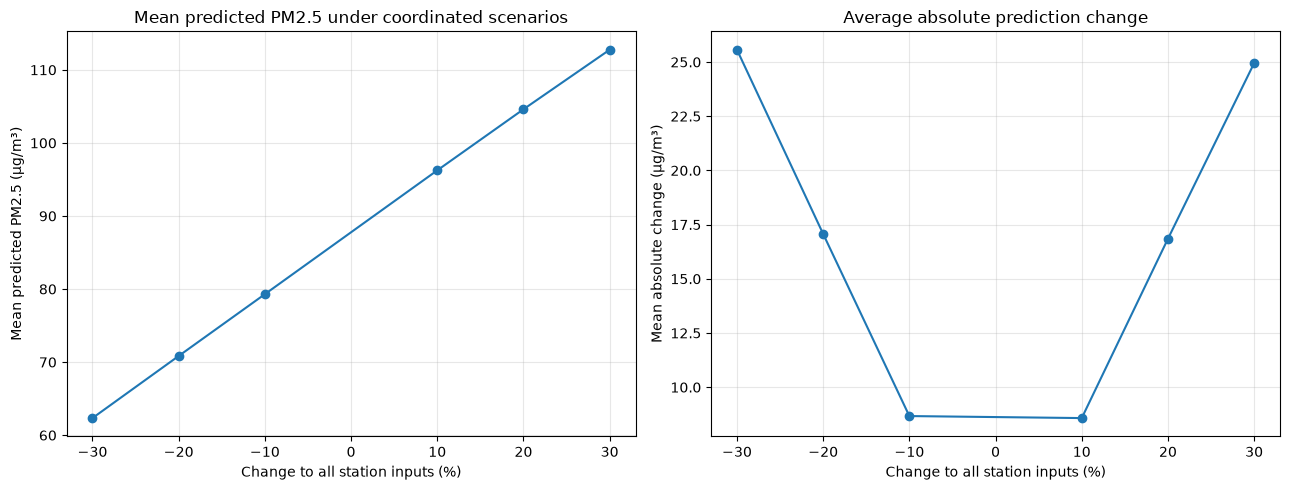

In [11]:
import matplotlib.pyplot as plt

coordinated = scenario_results[
    scenario_results["Scenario"].str.startswith("All 12 stations:")
].copy()

coordinated["Input_Change_Percent"] = (
    coordinated["Input_Change_Percent"].astype(float)
)

coordinated = coordinated.sort_values("Input_Change_Percent")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    coordinated["Input_Change_Percent"],
    coordinated["Mean_Prediction"],
    marker="o"
)
axes[0].set_title("Mean predicted PM2.5 under coordinated scenarios")
axes[0].set_xlabel("Change to all station inputs (%)")
axes[0].set_ylabel("Mean predicted PM2.5 (µg/m³)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    coordinated["Input_Change_Percent"],
    coordinated["Mean_Absolute_Change"],
    marker="o"
)
axes[1].set_title("Average absolute prediction change")
axes[1].set_xlabel("Change to all station inputs (%)")
axes[1].set_ylabel("Mean absolute change (µg/m³)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
scenario_report = REPORTS_DIR / "what_if_scenario_summary.csv"
scenario_detail_report = REPORTS_DIR / "what_if_scenario_predictions.csv"

scenario_results.to_csv(scenario_report, index=False)

detail_rows = []

for scenario_name, predictions in scenario_predictions.items():
    detail_rows.append(pd.DataFrame({
        "Target_Time": diagnostics["Target_Time"],
        "Scenario": scenario_name,
        "Actual_PM25": diagnostics["Actual_PM25"],
        "Baseline_Prediction": baseline_predictions,
        "Scenario_Prediction": predictions,
        "Prediction_Change": predictions - baseline_predictions,
    }))

scenario_details = pd.concat(detail_rows, ignore_index=True)
scenario_details.to_csv(scenario_detail_report, index=False)

print("Saved:", scenario_report)
print("Saved:", scenario_detail_report)
print("Scenario count:", len(scenario_results))
print("Prediction rows saved:", len(scenario_details))

Saved: C:\UrbanPulse-AI\reports\what_if_scenario_summary.csv
Saved: C:\UrbanPulse-AI\reports\what_if_scenario_predictions.csv
Scenario count: 18
Prediction rows saved: 92502


### Scenario Sensitivity Analysis

The coordinated perturbation experiment examined the sensitivity of the trained multi-station Random Forest model to hypothetical changes in PM2.5 measurements from all 12 monitoring stations. The mean predicted concentration increased from approximately 62.3 µg/m³ under a 30% reduction in station inputs to 112.8 µg/m³ under a 30% increase. Predictions also changed monotonically across the six tested perturbation levels.

The mean absolute prediction change increased with perturbation magnitude, reaching approximately 25 µg/m³ under the ±30% scenarios and approximately 8.6–8.7 µg/m³ under the ±10% scenarios. This indicates that larger coordinated changes in the model inputs produced larger changes in its forecasts over the evaluated test observations.

Individual-station perturbations produced different responses. Changes to Aotizhongxin inputs had a substantially greater average effect on predictions than changes to Dingling inputs, consistent with the earlier feature-importance analysis. These results describe the fitted model's sensitivity to the tested inputs; they do not establish causal effects, physical realism, calibration, or robustness under all possible conditions.

The analysis is limited to hypothetical input scaling. Future work should examine whether the modified inputs fall within the training data's observed ranges and evaluate scenarios that are more representative of plausible environmental conditions.

In [13]:
# Compare scenario inputs with the observed training-input ranges.
train_inputs = X_all.loc[train_mask, station_features]

range_rows = []

for feature in station_features:
    observed = train_inputs[feature].dropna()

    range_rows.append({
        "Station": feature,
        "Training_Min": observed.min(),
        "Training_Max": observed.max(),
        "Training_P01": observed.quantile(0.01),
        "Training_P99": observed.quantile(0.99),
    })

training_ranges = pd.DataFrame(range_rows).set_index("Station")

display(training_ranges.round(2))

,Training_Min,Training_Max,Training_P01,Training_P99
Station,,,,
Aotizhongxin,3.0,665.0,3.0,349.18
Changping,2.0,581.0,3.0,312.00
Dingling,3.0,548.0,3.0,319.01
Dongsi,3.0,737.0,3.0,363.90
Guanyuan,3.0,680.0,3.0,345.00
Gucheng,2.0,770.0,3.0,347.16
Huairou,2.0,762.0,3.0,308.00
Nongzhanguan,3.0,844.0,3.0,375.00
Shunyi,3.0,689.0,3.0,344.00


In [14]:
# Audit the input values used in every what-if scenario.

audit_rows = []

for scenario_name, predictions in scenario_predictions.items():
    X_scenario = X_scenario_base.copy()

    # Reconstruct the input changes represented by this scenario.
    if scenario_name.startswith("All 12 stations:"):
        change_text = scenario_name.split(": ")[1]
        change = float(change_text.replace("%", "")) / 100
        features_to_change = station_features

    elif scenario_name.startswith("Aotizhongxin only:"):
        change_text = scenario_name.split(": ")[1]
        change = float(change_text.replace("%", "")) / 100
        features_to_change = ["Aotizhongxin"]

    elif scenario_name.startswith("Dingling only:"):
        change_text = scenario_name.split(": ")[1]
        change = float(change_text.replace("%", "")) / 100
        features_to_change = ["Dingling"]

    else:
        continue

    for feature in features_to_change:
        observed = X_scenario[feature].notna()
        X_scenario.loc[observed, feature] *= (1 + change)

    for feature in station_features:
        values = X_scenario[feature].dropna()
        limits = training_ranges.loc[feature]

        audit_rows.append({
            "Scenario": scenario_name,
            "Station": feature,
            "Values_Checked": len(values),
            "Below_Training_Min": int(
                (values < limits["Training_Min"]).sum()
            ),
            "Above_Training_Max": int(
                (values > limits["Training_Max"]).sum()
            ),
            "Below_P01": int(
                (values < limits["Training_P01"]).sum()
            ),
            "Above_P99": int(
                (values > limits["Training_P99"]).sum()
            ),
        })

scenario_input_audit = pd.DataFrame(audit_rows)

display(scenario_input_audit.head(24))

audit_path = REPORTS_DIR / "what_if_input_range_audit.csv"
scenario_input_audit.to_csv(audit_path, index=False)

print("Saved:", audit_path)
print("Scenario-station combinations:", len(scenario_input_audit))

,Scenario,Station,Values_Checked,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,All 12 stations: -30%,Aotizhongxin,5139,143,0,143,18
1,All 12 stations: -30%,Changping,5115,0,0,109,28
2,All 12 stations: -30%,Dingling,4955,235,0,235,3
3,All 12 stations: -30%,Dongsi,4995,88,0,88,27
4,All 12 stations: -30%,Guanyuan,5074,117,0,117,28
5,All 12 stations: -30%,Gucheng,5075,0,0,111,55
6,All 12 stations: -30%,Huairou,5089,1,0,241,17
7,All 12 stations: -30%,Nongzhanguan,5086,172,0,172,22
8,All 12 stations: -30%,Shunyi,5024,208,0,208,29
9,All 12 stations: -30%,Tiantan,5099,145,0,145,23


Saved: C:\UrbanPulse-AI\reports\what_if_input_range_audit.csv
Scenario-station combinations: 216


In [15]:
audit_summary = (
    scenario_input_audit
    .groupby("Scenario", as_index=False)
    .agg(
        Values_Checked=("Values_Checked", "sum"),
        Below_Training_Min=("Below_Training_Min", "sum"),
        Above_Training_Max=("Above_Training_Max", "sum"),
        Below_P01=("Below_P01", "sum"),
        Above_P99=("Above_P99", "sum"),
    )
)

display(audit_summary)

,Scenario,Values_Checked,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,All 12 stations: +10%,60857,9,34,10,1944
1,All 12 stations: +20%,60857,9,81,10,2489
2,All 12 stations: +30%,60857,9,167,10,3139
3,All 12 stations: -10%,60857,970,4,1268,1009
4,All 12 stations: -20%,60857,970,0,1268,629
5,All 12 stations: -30%,60857,1416,0,1876,300
6,Aotizhongxin only: +10%,60857,9,14,10,1529
7,Aotizhongxin only: +20%,60857,9,17,10,1582
8,Aotizhongxin only: +30%,60857,9,24,10,1634
9,Aotizhongxin only: -10%,60857,120,9,121,1438


In [16]:
# Build a clean, correctly aligned audit of every scenario.
audit_rows = []

for scenario_name in scenario_predictions:
    X_scenario = X_scenario_base.copy()

    if scenario_name.startswith("All 12 stations:"):
        change = float(scenario_name.split(": ")[1].replace("%", "")) / 100
        changed_features = station_features
    elif scenario_name.startswith("Aotizhongxin only:"):
        change = float(scenario_name.split(": ")[1].replace("%", "")) / 100
        changed_features = ["Aotizhongxin"]
    elif scenario_name.startswith("Dingling only:"):
        change = float(scenario_name.split(": ")[1].replace("%", "")) / 100
        changed_features = ["Dingling"]
    else:
        continue

    for feature in changed_features:
        observed = X_scenario[feature].notna()
        X_scenario.loc[observed, feature] = (
            X_scenario.loc[observed, feature] * (1 + change)
        )

    for feature in station_features:
        values = X_scenario[feature].dropna()
        limits = training_ranges.loc[feature]

        audit_rows.append({
            "Scenario": scenario_name,
            "Station": feature,
            "Values_Checked": int(len(values)),
            "Below_Training_Min": int((values < limits["Training_Min"]).sum()),
            "Above_Training_Max": int((values > limits["Training_Max"]).sum()),
            "Below_P01": int((values < limits["Training_P01"]).sum()),
            "Above_P99": int((values > limits["Training_P99"]).sum()),
        })

scenario_input_audit = pd.DataFrame(audit_rows)

scenario_audit_summary = (
    scenario_input_audit.groupby("Scenario", sort=False)
    .agg(
        Station_Value_Count=("Values_Checked", "sum"),
        Below_Training_Min=("Below_Training_Min", "sum"),
        Above_Training_Max=("Above_Training_Max", "sum"),
        Below_P01=("Below_P01", "sum"),
        Above_P99=("Above_P99", "sum"),
    )
    .reset_index()
)

display(scenario_audit_summary.round(0))

scenario_input_audit.to_csv(
    REPORTS_DIR / "what_if_input_range_audit.csv",
    index=False
)
scenario_audit_summary.to_csv(
    REPORTS_DIR / "what_if_input_range_audit_summary.csv",
    index=False
)

print("Detailed audit rows:", len(scenario_input_audit))
print("Scenario summary rows:", len(scenario_audit_summary))

,Scenario,Station_Value_Count,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,All 12 stations: -30%,60857,1416,0,1876,300
1,All 12 stations: -20%,60857,970,0,1268,629
2,All 12 stations: -10%,60857,970,4,1268,1009
3,All 12 stations: +10%,60857,9,34,10,1944
4,All 12 stations: +20%,60857,9,81,10,2489
5,All 12 stations: +30%,60857,9,167,10,3139
6,Aotizhongxin only: -30%,60857,152,9,153,1377
7,Aotizhongxin only: -20%,60857,120,9,121,1406
8,Aotizhongxin only: -10%,60857,120,9,121,1438
9,Aotizhongxin only: +10%,60857,9,14,10,1529


Detailed audit rows: 216
Scenario summary rows: 18


In [17]:
display(
    scenario_audit_summary[
        scenario_audit_summary["Scenario"].str.startswith("All 12 stations:")
    ].round(0)
)

,Scenario,Station_Value_Count,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,All 12 stations: -30%,60857,1416,0,1876,300
1,All 12 stations: -20%,60857,970,0,1268,629
2,All 12 stations: -10%,60857,970,4,1268,1009
3,All 12 stations: +10%,60857,9,34,10,1944
4,All 12 stations: +20%,60857,9,81,10,2489
5,All 12 stations: +30%,60857,9,167,10,3139


In [18]:
# Rebuild a clean, correctly aligned scenario audit summary

scenario_audit_summary = (
    scenario_input_audit
    .groupby("Scenario", sort=False)
    .agg(
        Station_Value_Count=("Values_Checked", "sum"),
        Below_Training_Min=("Below_Training_Min", "sum"),
        Above_Training_Max=("Above_Training_Max", "sum"),
        Below_P01=("Below_P01", "sum"),
        Above_P99=("Above_P99", "sum"),
    )
    .reset_index()
)

print("Detailed audit rows:", len(scenario_input_audit))
print("Scenario summary rows:", len(scenario_audit_summary))

display(
    scenario_audit_summary[
        scenario_audit_summary["Scenario"].str.startswith("All 12 stations:")
    ].round(0)
)

scenario_input_audit.to_csv(
    REPORTS_DIR / "what_if_input_range_audit.csv",
    index=False
)

scenario_audit_summary.to_csv(
    REPORTS_DIR / "what_if_input_range_audit_summary.csv",
    index=False
)

Detailed audit rows: 216
Scenario summary rows: 18


,Scenario,Station_Value_Count,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,All 12 stations: -30%,60857,1416,0,1876,300
1,All 12 stations: -20%,60857,970,0,1268,629
2,All 12 stations: -10%,60857,970,4,1268,1009
3,All 12 stations: +10%,60857,9,34,10,1944
4,All 12 stations: +20%,60857,9,81,10,2489
5,All 12 stations: +30%,60857,9,167,10,3139


In [19]:
# Verify the audit directly for coordinated scenarios

for scenario_name in [
    "All 12 stations: -30%",
    "All 12 stations: -20%",
    "All 12 stations: -10%",
    "All 12 stations: +10%",
    "All 12 stations: +20%",
    "All 12 stations: +30%",
]:
    print(f"\n{scenario_name}")

    rows = scenario_input_audit[
        scenario_input_audit["Scenario"] == scenario_name
    ].copy()

    display(
        rows[
            [
                "Station",
                "Values_Checked",
                "Below_Training_Min",
                "Above_Training_Max",
                "Below_P01",
                "Above_P99",
            ]
        ].sort_values("Station").reset_index(drop=True)
    )


All 12 stations: -30%


,Station,Values_Checked,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,Aotizhongxin,5139,143,0,143,18
1,Changping,5115,0,0,109,28
2,Dingling,4955,235,0,235,3
3,Dongsi,4995,88,0,88,27
4,Guanyuan,5074,117,0,117,28
5,Gucheng,5075,0,0,111,55
6,Huairou,5089,1,0,241,17
7,Nongzhanguan,5086,172,0,172,22
8,Shunyi,5024,208,0,208,29
9,Tiantan,5099,145,0,145,23



All 12 stations: -20%


,Station,Values_Checked,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,Aotizhongxin,5139,111,0,111,47
1,Changping,5115,0,0,76,51
2,Dingling,4955,150,0,150,21
3,Dongsi,4995,63,0,63,64
4,Guanyuan,5074,71,0,71,62
5,Gucheng,5075,0,0,69,94
6,Huairou,5089,1,0,154,37
7,Nongzhanguan,5086,120,0,120,39
8,Shunyi,5024,144,0,144,54
9,Tiantan,5099,111,0,111,51



All 12 stations: -10%


...

,Station,Values_Checked,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,Aotizhongxin,5139,0,5,0,170
1,Changping,5115,0,8,0,129
2,Dingling,4955,0,2,0,77
3,Dongsi,4995,0,1,0,195
4,Guanyuan,5074,1,2,1,170
5,Gucheng,5075,0,2,0,177
6,Huairou,5089,0,0,1,123
7,Nongzhanguan,5086,2,1,2,166
8,Shunyi,5024,5,5,5,157
9,Tiantan,5099,0,3,0,208



All 12 stations: +20%


,Station,Values_Checked,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,Aotizhongxin,5139,0,8,0,223
1,Changping,5115,0,19,0,163
2,Dingling,4955,0,3,0,108
3,Dongsi,4995,0,9,0,248
4,Guanyuan,5074,1,6,1,210
5,Gucheng,5075,0,5,0,231
6,Huairou,5089,0,0,1,160
7,Nongzhanguan,5086,2,2,2,218
8,Shunyi,5024,5,9,5,211
9,Tiantan,5099,0,4,0,267



All 12 stations: +30%


,Station,Values_Checked,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,Aotizhongxin,5139,0,15,0,275
1,Changping,5115,0,28,0,225
2,Dingling,4955,0,12,0,148
3,Dongsi,4995,0,19,0,325
4,Guanyuan,5074,1,12,1,285
5,Gucheng,5075,0,17,0,288
6,Huairou,5089,0,0,1,211
7,Nongzhanguan,5086,2,3,2,262
8,Shunyi,5024,5,15,5,264
9,Tiantan,5099,0,16,0,318


In [20]:
scenario_name = "All 12 stations: +30%"

detail = scenario_input_audit[
    scenario_input_audit["Scenario"] == scenario_name
]

display(
    detail[
        [
            "Station",
            "Values_Checked",
            "Below_Training_Min",
            "Above_Training_Max",
            "Below_P01",
            "Above_P99",
        ]
    ].sum(numeric_only=True).to_frame("Station_Row_Sum")
)

display(
    scenario_audit_summary[
        scenario_audit_summary["Scenario"] == scenario_name
    ]
)

,Station_Row_Sum
Values_Checked,60857
Below_Training_Min,9
Above_Training_Max,167
Below_P01,10
Above_P99,3139


,Scenario,Station_Value_Count,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
5,All 12 stations: +30%,60857,9,167,10,3139


In [21]:
# Cell 1 — Final audit validation

import pandas as pd
import numpy as np

required_audit_columns = [
    "Scenario",
    "Station",
    "Values_Checked",
    "Below_Training_Min",
    "Above_Training_Max",
    "Below_P01",
    "Above_P99",
]

missing_columns = [
    col for col in required_audit_columns
    if col not in scenario_input_audit.columns
]

assert not missing_columns, f"Missing audit columns: {missing_columns}"
assert len(scenario_input_audit) == 216, (
    f"Expected 216 detailed audit rows, got {len(scenario_input_audit)}"
)

assert scenario_input_audit["Scenario"].nunique() == 18
assert scenario_input_audit["Station"].nunique() == 12

assert not scenario_input_audit.duplicated(
    ["Scenario", "Station"]
).any(), "Duplicate scenario-station combinations detected."

count_columns = [
    "Values_Checked",
    "Below_Training_Min",
    "Above_Training_Max",
    "Below_P01",
    "Above_P99",
]

assert (
    scenario_input_audit[count_columns].fillna(0) >= 0
).all().all(), "Negative audit counts detected."

scenario_audit_summary = (
    scenario_input_audit
    .groupby("Scenario", sort=False)
    .agg(
        Station_Value_Count=("Values_Checked", "sum"),
        Below_Training_Min=("Below_Training_Min", "sum"),
        Above_Training_Max=("Above_Training_Max", "sum"),
        Below_P01=("Below_P01", "sum"),
        Above_P99=("Above_P99", "sum"),
    )
    .reset_index()
)

assert len(scenario_audit_summary) == 18

print("Detailed audit rows:", len(scenario_input_audit))
print("Unique scenarios:", scenario_input_audit["Scenario"].nunique())
print("Unique stations:", scenario_input_audit["Station"].nunique())
print("Scenario-station duplicates:",
      scenario_input_audit.duplicated(["Scenario", "Station"]).sum())

display(scenario_audit_summary.round(0))

scenario_input_audit.to_csv(
    REPORTS_DIR / "what_if_input_range_audit.csv",
    index=False
)

scenario_audit_summary.to_csv(
    REPORTS_DIR / "what_if_input_range_audit_summary.csv",
    index=False
)

print("Final audit files saved.")

Detailed audit rows: 216
Unique scenarios: 18
Unique stations: 12
Scenario-station duplicates: 0


,Scenario,Station_Value_Count,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99
0,All 12 stations: -30%,60857,1416,0,1876,300
1,All 12 stations: -20%,60857,970,0,1268,629
2,All 12 stations: -10%,60857,970,4,1268,1009
3,All 12 stations: +10%,60857,9,34,10,1944
4,All 12 stations: +20%,60857,9,81,10,2489
5,All 12 stations: +30%,60857,9,167,10,3139
6,Aotizhongxin only: -30%,60857,152,9,153,1377
7,Aotizhongxin only: -20%,60857,120,9,121,1406
8,Aotizhongxin only: -10%,60857,120,9,121,1438
9,Aotizhongxin only: +10%,60857,9,14,10,1529


Final audit files saved.


In [22]:
# Cell 2 — Express range violations as percentages

audit_percentages = scenario_audit_summary.copy()

audit_percentages["Below_Min_Pct"] = (
    100 * audit_percentages["Below_Training_Min"]
    / audit_percentages["Station_Value_Count"]
)

audit_percentages["Above_Max_Pct"] = (
    100 * audit_percentages["Above_Training_Max"]
    / audit_percentages["Station_Value_Count"]
)

audit_percentages["Below_P01_Pct"] = (
    100 * audit_percentages["Below_P01"]
    / audit_percentages["Station_Value_Count"]
)

audit_percentages["Above_P99_Pct"] = (
    100 * audit_percentages["Above_P99"]
    / audit_percentages["Station_Value_Count"]
)

display(
    audit_percentages[
        [
            "Scenario",
            "Station_Value_Count",
            "Below_Min_Pct",
            "Above_Max_Pct",
            "Below_P01_Pct",
            "Above_P99_Pct",
        ]
    ].round(3)
)

audit_percentages.to_csv(
    REPORTS_DIR / "what_if_input_range_audit_percentages.csv",
    index=False
)

,Scenario,Station_Value_Count,Below_Min_Pct,Above_Max_Pct,Below_P01_Pct,Above_P99_Pct
0,All 12 stations: -30%,60857,2.327,0.000,3.083,0.493
1,All 12 stations: -20%,60857,1.594,0.000,2.084,1.034
2,All 12 stations: -10%,60857,1.594,0.007,2.084,1.658
3,All 12 stations: +10%,60857,0.015,0.056,0.016,3.194
4,All 12 stations: +20%,60857,0.015,0.133,0.016,4.090
5,All 12 stations: +30%,60857,0.015,0.274,0.016,5.158
6,Aotizhongxin only: -30%,60857,0.250,0.015,0.251,2.263
7,Aotizhongxin only: -20%,60857,0.197,0.015,0.199,2.310
8,Aotizhongxin only: -10%,60857,0.197,0.015,0.199,2.363
9,Aotizhongxin only: +10%,60857,0.015,0.023,0.016,2.512


In [23]:
# Cell 3 — Consolidate scenario results and audit

scenario_summary_final = scenario_results.copy()

scenario_summary_final = scenario_summary_final.merge(
    scenario_audit_summary,
    on="Scenario",
    how="left",
    validate="one_to_one"
)

scenario_summary_final = scenario_summary_final.merge(
    audit_percentages[
        [
            "Scenario",
            "Below_Min_Pct",
            "Above_Max_Pct",
            "Below_P01_Pct",
            "Above_P99_Pct",
        ]
    ],
    on="Scenario",
    how="left",
    validate="one_to_one"
)

assert len(scenario_summary_final) == 18
assert scenario_summary_final["Station_Value_Count"].notna().all()

display(scenario_summary_final.round(3))

scenario_summary_final.to_csv(
    REPORTS_DIR / "what_if_scenario_summary_final.csv",
    index=False
)

print("Saved:", REPORTS_DIR / "what_if_scenario_summary_final.csv")

,Scenario,Input_Change_Percent,Mean_Prediction,Mean_Signed_Change,Median_Signed_Change,Mean_Absolute_Change,P05_Change,P95_Change,Station_Value_Count,Below_Training_Min,Above_Training_Max,Below_P01,Above_P99,Below_Min_Pct,Above_Max_Pct,Below_P01_Pct,Above_P99_Pct
0,All 12 stations: -30%,-30.0,62.342,-25.535,-16.375,25.567,-80.367,-1.779,60857,1416,0,1876,300,2.327,0.000,3.083,0.493
1,All 12 stations: -20%,-20.0,70.841,-17.037,-10.675,17.070,-55.318,-0.986,60857,970,0,1268,629,1.594,0.000,2.084,1.034
2,All 12 stations: -10%,-10.0,79.298,-8.579,-5.115,8.670,-29.200,-0.379,60857,970,4,1268,1009,1.594,0.007,2.084,1.658
3,All 12 stations: +10%,10.0,96.244,8.366,4.728,8.577,0.233,28.630,60857,9,34,10,1944,0.015,0.056,0.016,3.194
4,All 12 stations: +20%,20.0,104.602,16.725,10.397,16.848,1.066,53.351,60857,9,81,10,2489,0.015,0.133,0.016,4.090
5,All 12 stations: +30%,30.0,112.751,24.873,15.898,24.950,1.663,78.263,60857,9,167,10,3139,0.015,0.274,0.016,5.158
6,Aotizhongxin only: -30%,-30.0,70.436,-17.441,-8.596,17.656,-66.462,0.000,60857,152,9,153,1377,0.250,0.015,0.251,2.263
7,Aotizhongxin only: -20%,-20.0,76.045,-11.832,-5.789,12.055,-46.352,0.011,60857,120,9,121,1406,0.197,0.015,0.199,2.310
8,Aotizhongxin only: -10%,-10.0,82.046,-5.832,-2.500,6.084,-22.817,0.145,60857,120,9,121,1438,0.197,0.015,0.199,2.363
9,Aotizhongxin only: +10%,10.0,93.070,5.192,2.264,5.521,-0.184,20.053,60857,9,14,10,1529,0.015,0.023,0.016,2.512


Saved: C:\UrbanPulse-AI\reports\what_if_scenario_summary_final.csv


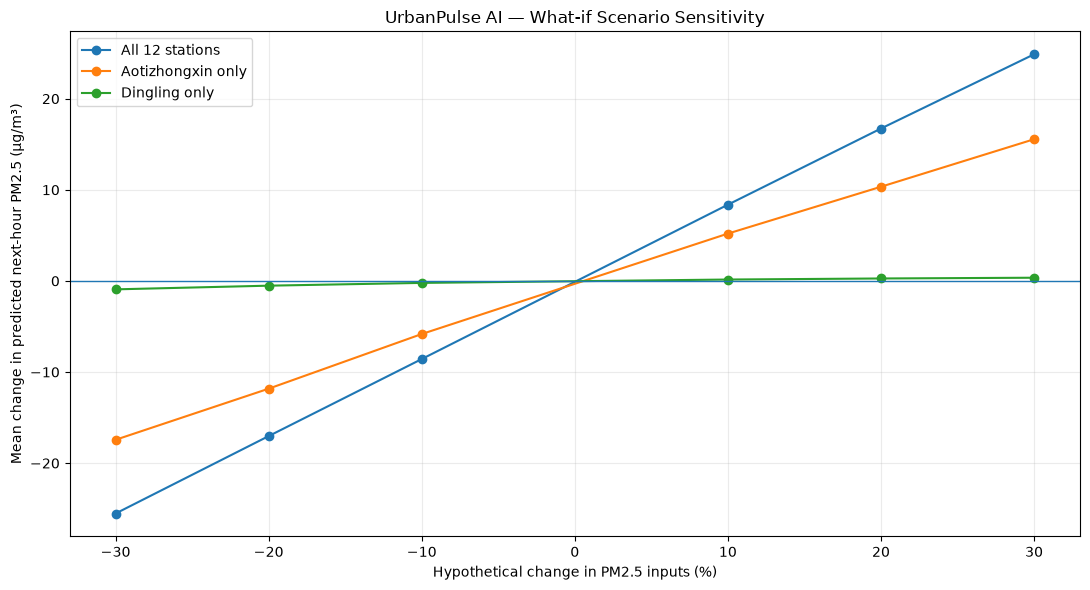

In [24]:
# Cell 4 — Plot mean signed changes

import matplotlib.pyplot as plt

plot_data = scenario_results.copy()

scenario_col = "Scenario"
change_col = "Mean_Signed_Change"

assert scenario_col in plot_data.columns, plot_data.columns.tolist()
assert change_col in plot_data.columns, plot_data.columns.tolist()

plot_data["Scenario_Type"] = np.select(
    [
        plot_data["Scenario"].str.startswith("All 12 stations:"),
        plot_data["Scenario"].str.startswith("Aotizhongxin only:"),
        plot_data["Scenario"].str.startswith("Dingling only:"),
    ],
    [
        "All 12 stations",
        "Aotizhongxin only",
        "Dingling only",
    ],
    default="Other"
)

plot_data["Change_Percent"] = (
    plot_data["Scenario"]
    .str.extract(r"([+-]?\d+)%")[0]
    .astype(float)
)

fig, ax = plt.subplots(figsize=(11, 6))

for scenario_type, group in plot_data.groupby("Scenario_Type", sort=False):
    group = group.sort_values("Change_Percent")
    ax.plot(
        group["Change_Percent"],
        group[change_col],
        marker="o",
        label=scenario_type
    )

ax.axhline(0, linewidth=1)
ax.set_title("UrbanPulse AI — What-if Scenario Sensitivity")
ax.set_xlabel("Hypothetical change in PM2.5 inputs (%)")
ax.set_ylabel("Mean change in predicted next-hour PM2.5 (µg/m³)")
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / "what_if_scenario_sensitivity.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

## 8. Final Results and Limitations

### 8.1 Objective

The what-if engine evaluates how the trained multi-station Random Forest forecasting model responds to hypothetical percentage changes in observed PM2.5 concentrations. It applies perturbations to all twelve monitoring stations, Aotizhongxin alone, and Dingling alone, while keeping other inputs unchanged for single-station scenarios.

### 8.2 Main Findings

The coordinated scenarios show that the model's predicted next-hour PM2.5 changes as the input concentrations are perturbed. The magnitude of the response depends on the size of the perturbation and the set of stations being modified.

The single-station scenarios also demonstrate that the model responds differently to perturbations at different monitoring stations. These differences are consistent with the previously calculated feature-importance and permutation-importance results, but they should not be treated as independent evidence of causal influence.

### 8.3 Input-Range Audit

Each hypothetical scenario was checked against the training distribution. The audit records the number of non-missing station readings falling below the training minimum, above the training maximum, below the training first percentile, and above the training ninety-ninth percentile.

The coordinated positive perturbations produce an increasing number of readings above the training ninety-ninth percentile. Some modified readings also exceed the training maximum. Negative perturbations can move readings below the training minimum.

These checks identify potential distribution shift. They do not establish whether a complete twelve-station input vector is historically plausible because the audit checks each station's marginal distribution rather than the joint distribution across stations.

### 8.4 Interpretation Boundaries

The what-if engine measures model sensitivity to hypothetical inputs. It does not estimate the causal effect of an emissions policy, traffic intervention, industrial control measure, or other real-world action.

The scenarios assume that the selected input concentrations can be changed while the remaining conditions stay fixed. Actual environmental interventions could also change weather, emissions, transport, and concentrations at multiple locations simultaneously.

The model's responses should therefore be presented as conditional model outputs rather than guaranteed pollution reductions or intervention forecasts.

### 8.5 Limitations

- The underlying dataset represents historical observations from Beijing between March 2013 and February 2017.
- The analysis relies on the trained Random Forest and the available monitoring-station features.
- Percentage perturbations may create inputs outside the training distribution.
- Marginal range checks do not verify joint physical or meteorological plausibility.
- The engine does not simulate atmospheric chemistry, emissions transport, or causal intervention mechanisms.
- Prediction uncertainty is not fully represented by the scenario mean alone.

### 8.6 Conclusion

The what-if engine extends UrbanPulse AI from forecasting historical observations to evaluating the sensitivity of its forecasting model under hypothetical input changes. Together with the earlier forecasting, anomaly-detection, spatial-modeling, and explainability experiments, it provides a foundation for an interactive exploratory dashboard.

The resulting tool should clearly distinguish measured historical data, model predictions, and hypothetical scenario outputs. Further validation using additional locations, later observations, and physically informed intervention scenarios would be needed before making operational policy claims.

In [25]:
# Cell 5 — Milestone 8 artifact verification

expected_files = [
    "what_if_scenario_summary.csv",
    "what_if_scenario_predictions.csv",
    "what_if_input_range_audit.csv",
    "what_if_input_range_audit_summary.csv",
    "what_if_input_range_audit_percentages.csv",
    "what_if_scenario_summary_final.csv",
    "what_if_scenario_sensitivity.png",
]

artifact_status = []

for filename in expected_files:
    path = REPORTS_DIR / filename
    artifact_status.append({
        "Artifact": filename,
        "Exists": path.exists(),
        "Size_Bytes": path.stat().st_size if path.exists() else None,
    })

artifact_check = pd.DataFrame(artifact_status)
display(artifact_check)

missing_artifacts = artifact_check.loc[
    ~artifact_check["Exists"], "Artifact"
].tolist()

if missing_artifacts:
    print("Artifacts not created yet:", missing_artifacts)
else:
    print("Milestone 8 report artifacts verified.")

,Artifact,Exists,Size_Bytes
0,what_if_scenario_summary.csv,True,2684
1,what_if_scenario_predictions.csv,True,9622298
2,what_if_input_range_audit.csv,True,10405
3,what_if_input_range_audit_summary.csv,True,868
4,what_if_input_range_audit_percentages.csv,True,2308
5,what_if_scenario_summary_final.csv,True,4568
6,what_if_scenario_sensitivity.png,True,94866


Milestone 8 report artifacts verified.
